In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
from google.colab import files

uploaded = files.upload()

# Read the uploaded CSV file
df = pd.read_csv(next(iter(uploaded)))

# Display the first 5 rows
print(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns)
print("\nMissing Values:\n", df.isnull().sum())

Saving WineQT.csv to WineQT.csv
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1 

**Separate features and target**

In [3]:
# Separate input features and target variable
X = df.drop('quality', axis=1)
y = df['quality']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (1143, 12)
Target shape: (1143,)


**Standardize the data **

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (1143, 12)


**Apply PCA**

In [5]:
# Apply PCA
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original data shape:", X_scaled.shape)
print("PCA-transformed data shape:", X_pca.shape)

# Display explained variance ratio
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

# Display cumulative explained variance
print("\nCumulative Explained Variance:")
print(np.cumsum(pca.explained_variance_ratio_))

Original data shape: (1143, 12)
PCA-transformed data shape: (1143, 12)

Explained Variance Ratio:
[0.27194409 0.15872089 0.13585374 0.10096166 0.08046427 0.07449103
 0.05187962 0.04467196 0.03480083 0.02701673 0.01435664 0.00483854]

Cumulative Explained Variance:
[0.27194409 0.43066498 0.56651872 0.66748038 0.74794465 0.82243568
 0.8743153  0.91898726 0.9537881  0.98080482 0.99516146 1.        ]


**Plot explained variance**

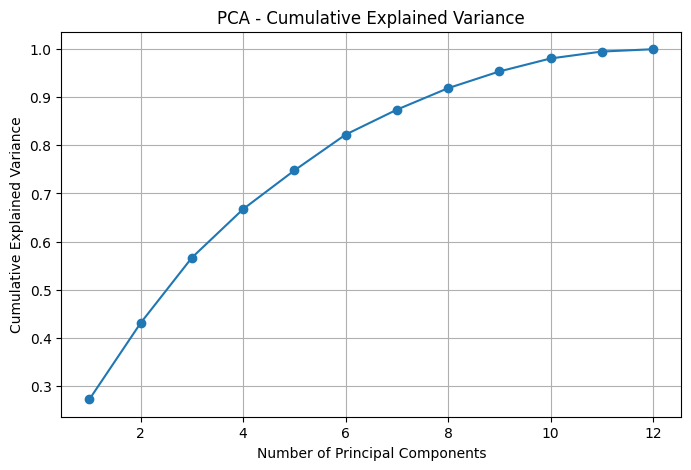

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')
plt.grid(True)

plt.show()

**Reduce the data to 2 principal components**

In [7]:
# Apply PCA with 2 components
pca_2 = PCA(n_components=2)

X_pca_2 = pca_2.fit_transform(X_scaled)

# Create a new DataFrame
pca_df = pd.DataFrame(
    X_pca_2,
    columns=['PC1', 'PC2']
)

# Add the wine quality target
pca_df['quality'] = y.to_numpy()

print(pca_df.head())

print("\nExplained variance by PC1 and PC2:")
print(pca_2.explained_variance_ratio_)

print(
    "\nTotal variance explained:",
    round(pca_2.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

        PC1       PC2  quality
0 -1.078814  1.033899        5
1 -0.307332  2.289875        5
2 -0.265776  1.348870        5
3  2.617729 -0.099643        6
4 -1.080670  1.032473        5

Explained variance by PC1 and PC2:
[0.27194409 0.15872089]

Total variance explained: 43.07 %


**Visualize the PCA results**

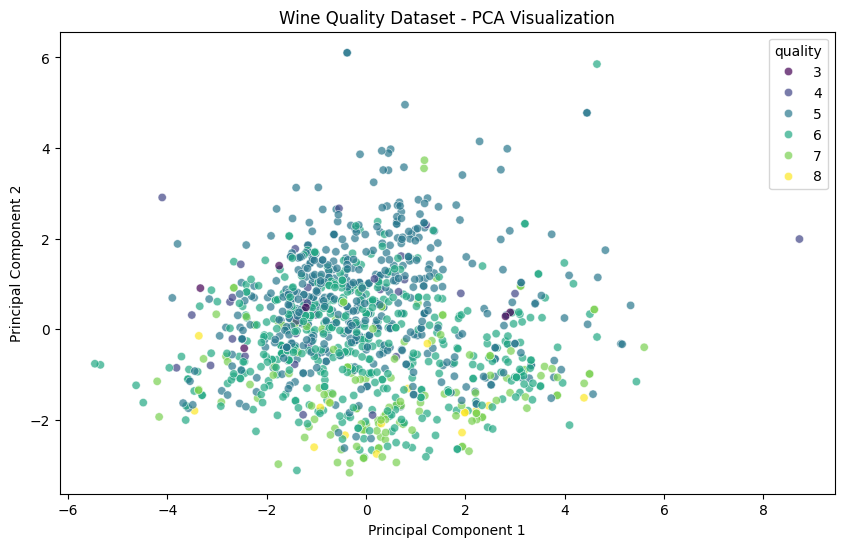

In [8]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='quality',
    palette='viridis',
    alpha=0.7
)

plt.title('Wine Quality Dataset - PCA Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

**Question 1: What happens if we change the number of components?**

In [9]:
from sklearn.decomposition import PCA

# Apply PCA with 2 components
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)

print("Shape with 2 components:", X_pca2.shape)
print("Variance retained with 2 components:",
      pca2.explained_variance_ratio_.sum() * 100, "%")

# Apply PCA with 3 components
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

print("\nShape with 3 components:", X_pca3.shape)
print("Variance retained with 3 components:",
      pca3.explained_variance_ratio_.sum() * 100, "%")

Shape with 2 components: (1143, 2)
Variance retained with 2 components: 43.06649780308679 %

Shape with 3 components: (1143, 3)
Variance retained with 3 components: 56.65187172585151 %


**Q1(a).How many features are present after reduction?**

When PCA uses 2 components, the dataset has 2 features. When PCA uses 3 components, the dataset has 3 features.

**Q1(b). Does the number of samples change?**

No. The number of samples remains 1,143 because PCA reduces the number of features, not the number of samples.

**Q1(c). Does the total variance retained increase or decrease?**

The total variance retained increases from 43.07% with 2 components to 56.65% with 3 components. The third principal component captures additional information about the variation in the dataset.

**Question 2 — What happens if standardization is removed?**

In [10]:
from sklearn.decomposition import PCA #AP24110010992

# PCA using standardized data
pca_scaled = PCA(n_components=2)
pca_scaled.fit(X_scaled)

print("Standardized data:")
print(pca_scaled.explained_variance_ratio_ * 100)
print("Total variance retained:",
      pca_scaled.explained_variance_ratio_.sum() * 100, "%")


# PCA using original, unstandardized data
pca_original = PCA(n_components=2)
pca_original.fit(X)

print("\nUnstandardized data:")
print(pca_original.explained_variance_ratio_ * 100)
print("Total variance retained:",
      pca_original.explained_variance_ratio_.sum() * 100, "%")

Standardized data:
[27.19440861 15.87208919]
Total variance retained: 43.06649780308679 %

Unstandardized data:
[99.4585047  0.514061 ]
Total variance retained: 99.9725657034828 %


**Q2(a). Does the explained variance ratio change?**

Yes. With standardized data, the first two components retain 43.07% of the variance. Without standardization, they retain 99.97%. This happens because the features have different scales, and features with larger numerical variability can dominate PCA when standardization is removed.

**Q2(b). Why might features with larger numerical scales influence PCA more strongly?**

PCA identifies directions of maximum variance. Features with larger numerical variability can contribute more strongly to the variance calculation and dominate the principal components. Standardization reduces this scale-related effect.

**Q2(c). Is standardization always necessary?**

No. Standardization is generally recommended when features have different units or scales. However, it may not be necessary when all features already have comparable scales or when their original scales are intentionally meaningful.

**Question 3 — What happens if we retain more components?**

In [11]:
#AP24110010992
# Find the minimum number of components
# required to retain at least 90% variance

pca_full = PCA()
pca_full.fit(X_scaled)

cumulative_variance = pca_full.explained_variance_ratio_.cumsum()

n_components_90 = (
    (cumulative_variance >= 0.90).argmax() + 1
)

print("Components needed for 90% variance:",
      n_components_90)

print("Variance retained:",
      cumulative_variance[n_components_90 - 1] * 100, "%")

Components needed for 90% variance: 8
Variance retained: 91.89872621802458 %


**Q3(a). How does the cumulative explained variance change?**

Cumulative explained variance generally increases as the number of principal components increases. Each additional component captures some additional variance from the dataset. Therefore, retaining more components preserves more information from the original features.

**Q3(b). How many components are needed to retain at least 90% of the variance?**

According to my experimental result, 8 principal components are required to retain at least 90% of the variance. These components retain approximately 91.90% of the total variance.

**Q3(c). Is reducing to two components always the best choice?**

No. Reducing the dataset to two components is useful for visualizing data in two dimensions, but it may result in significant information loss. In my experiment, two components retain only 43.07% of the variance. Using eight components retains approximately 91.90%, making it more suitable when preserving information is important.

In [12]:
#AP24110010992
from sklearn.decomposition import PCA

components = [1, 2, 3, 5, 10]

for n in components:
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X_scaled)

    variance = pca.explained_variance_ratio_.sum() * 100

    print(f"Components: {n}")
    print(f"Reduced shape: {X_pca.shape}")
    print(f"Cumulative variance: {variance:.2f}%")
    print("-" * 30)

Components: 1
Reduced shape: (1143, 1)
Cumulative variance: 27.19%
------------------------------
Components: 2
Reduced shape: (1143, 2)
Cumulative variance: 43.07%
------------------------------
Components: 3
Reduced shape: (1143, 3)
Cumulative variance: 56.65%
------------------------------
Components: 5
Reduced shape: (1143, 5)
Cumulative variance: 74.79%
------------------------------
Components: 10
Reduced shape: (1143, 10)
Cumulative variance: 98.08%
------------------------------


**Question 4 — What happens to the visualization?**

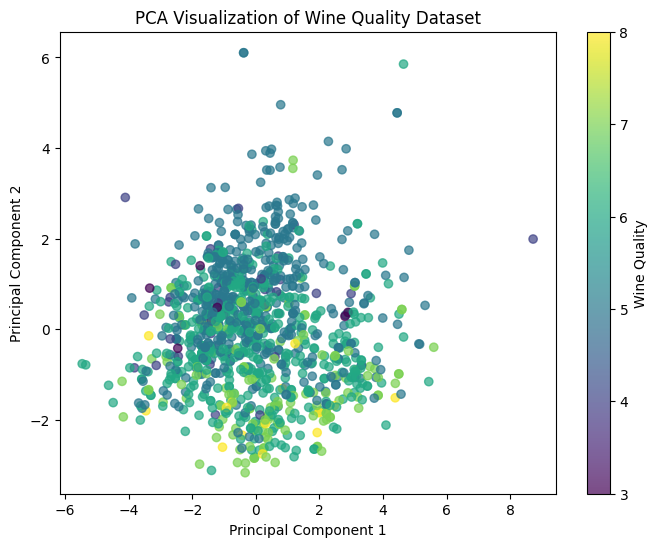

In [13]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce the standardized data to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a scatter plot
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Wine Quality Dataset")

plt.colorbar(scatter, label="Wine Quality")
plt.show()

**1. Are the wine quality classes clearly separated?**

No, the wine quality classes are not clearly separated in the plot. Different quality values overlap significantly, especially around the center of the graph. This indicates that the first two principal components do not clearly distinguish all wine quality levels.

**2. What information might be lost when reducing 11 features to 2?**

Reducing 11 original features to 2 principal components may cause information loss. In our experiment, the first two components retain approximately 43.07% of the total variance, meaning approximately 56.93% is not represented by these two components.

**3. Does PCA use the class labels to create the components?**

No. PCA is an unsupervised dimensionality-reduction technique. It uses the input features to calculate principal components without using the target labels. In our graph, wine quality is used only to color the points.

**Question 5 — Does PCA select existing features?**

**1. Are the two principal components original Wine dataset columns?**

No. The two principal components are new features created by combining information from the original input features. They are not original columns such as alcohol, density, or sulphates.

**2. What is the difference between feature selection and feature extraction?
Answer:**

| Feature selection | Feature extraction |
|---|---|
| Selects existing features from the dataset. | Creates new features from the original features. |
| Original feature meanings are preserved. | New features may be harder to interpret. |
| Example: selecting alcohol and density. | Example: transforming the original features into PC1 and PC2 using PCA. |

**3. Why is PCA considered a feature extraction technique?**

PCA is a feature extraction technique because it transforms the original input features into new features called principal components. These components capture directions of variance in the data and can reduce dimensionality while retaining important information.